# 07 · Interpretation of the global model with Shapley values

Supports **Section 7.8** of the thesis. The Shapley values are computed by `python src/interpretation.py`
(XGBoost's exact TreeSHAP); this notebook only reads them.

**What is explained.** The forecasts of the test window (4 weekly origins × 7 horizons) of a random sample
of 4,000 series, 112,000 forecasts in all, for the best variant (L+E+S+ID, Tweedie) and for the same model
without the identifiers (L+E+S, Tweedie).

**How to read the values.** The model has a log link, so the contributions are on the log scale: the base
value plus the contributions of a forecast add up to the logarithm of the forecast. A contribution of +0.10
multiplies the forecast by e^0.10 ≈ 1.11, one of −0.10 by 0.90. The importance of an input is the mean of
the absolute value of its contribution over the forecasts; the importance of a group of inputs is the mean
absolute value of the sum of the contributions of its inputs.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import features as F
import m5_data as m5
from plot_style import BLUE_RAMP, SERIES, apply_style, savefig

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SHAP = m5.PROCESSED_DIR / "shap"
RESULTS = ROOT / "results" / "interpretation"
RESULTS.mkdir(parents=True, exist_ok=True)
NAMES = {"LESID_tweedie": "L+E+S+ID · Tweedie", "LES_tweedie": "L+E+S · Tweedie"}
GROUP_NAMES = {"h": "horizon", "L": "L: lags of sales", "E": "E: known in advance", "S": "S: statistics of sales",
               "ID": "ID: identifiers"}
CLASSES = ["smooth", "erratic", "intermittent", "lumpy"]

X = pd.read_parquet(SHAP / "inputs.parquet")
series = np.load(SHAP / "series.npy")
stats = pd.read_parquet(m5.PROCESSED_DIR / "series_stats_train.parquet")
cls = stats["sbc_class"].astype(str).to_numpy()[series]
group_of = {F.H_COL: "h"} | {c: g for g, cols in F.GROUPS.items() for c in cols}
shap, base = {}, {}
for key, name in NAMES.items():
    z = np.load(SHAP / f"{key}.npz")
    shap[name] = pd.DataFrame(z["contrib"], columns=z["columns"])
    base[name] = float(z["base"][0])
TOP = NAMES["LESID_tweedie"]
print(f"{len(X):,} forecasts of {len(np.unique(series)):,} series; base value of {TOP}: {base[TOP]:.3f} (forecast {np.exp(base[TOP]):.3f} units)")
pd.Series(cls).value_counts().div(28).loc[CLASSES].rename("series in the sample").to_frame().T

112,000 forecasts of 4,000 series; base value of L+E+S+ID · Tweedie: 0.324 (forecast 1.382 units)


,smooth,erratic,intermittent,lumpy
series in the sample,252.000,113.000,"2,927.000",708.000


## 1. Importance of the groups of inputs

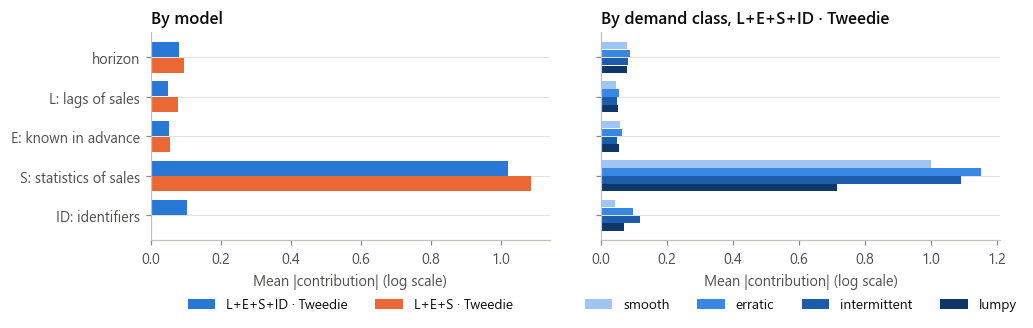

,L+E+S+ID · Tweedie,L+E+S · Tweedie,L+E+S+ID · Tweedie · smooth,L+E+S+ID · Tweedie · erratic,L+E+S+ID · Tweedie · intermittent,L+E+S+ID · Tweedie · lumpy
horizon,0.080,0.096,0.080,0.088,0.081,0.078
L: lags of sales,0.048,0.076,0.046,0.053,0.047,0.051
E: known in advance,0.051,0.055,0.058,0.063,0.050,0.055
S: statistics of sales,1.021,1.086,1.000,1.153,1.091,0.716
ID: identifiers,0.103,NaN,0.043,0.096,0.117,0.070


In [2]:
def group_importance(s, mask=None):
    s = s if mask is None else s[mask]
    g = s.T.groupby([group_of[c] for c in s.columns]).sum().T
    return g.abs().mean().reindex(list(GROUP_NAMES)).rename(GROUP_NAMES)


groups = pd.DataFrame({name: group_importance(s) for name, s in shap.items()})
by_class = pd.DataFrame({c: group_importance(shap[TOP], cls == c) for c in CLASSES})
groups.to_csv(RESULTS / "group_importance.csv")
by_class.to_csv(RESULTS / "group_importance_by_class.csv")
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2))
y = np.arange(len(groups))[::-1]
for k, (name, color) in enumerate(zip(groups.columns, SERIES)):
    axes[0].barh(y + (0.2 - 0.4 * k), groups[name].fillna(0), 0.38, color=color, label=name)
axes[0].set_yticks(y, groups.index)
axes[0].set_xlabel("Mean |contribution| (log scale)")
axes[0].set_title("By model")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncols=2)
for k, (c, color) in enumerate(zip(CLASSES, BLUE_RAMP[1::2])):
    axes[1].barh(y + (0.3 - 0.2 * k), by_class[c], 0.19, color=color, label=c)
axes[1].set_yticks(y, [])
axes[1].set_xlabel("Mean |contribution| (log scale)")
axes[1].set_title(f"By demand class, {TOP}")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncols=4)
fig.tight_layout()
savefig(fig, "group_importance", subdir="interpretation")
plt.show()
pd.concat([groups, by_class.add_prefix(f"{TOP} · ")], axis=1)

## 2. Single inputs

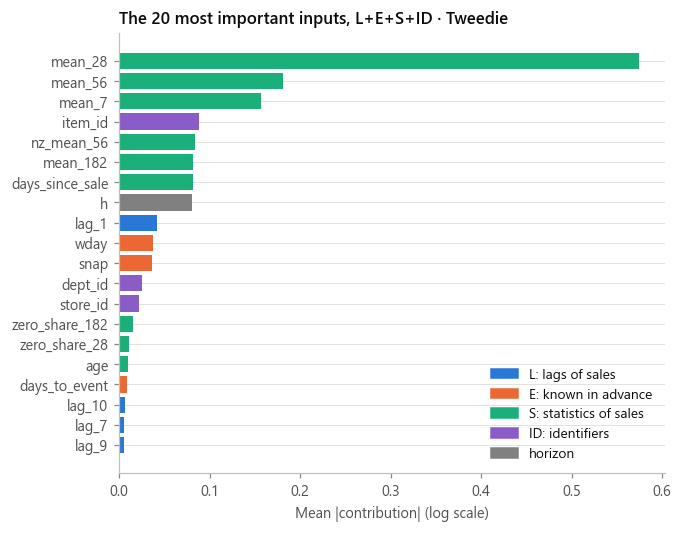

the 10 most important inputs carry 86% of the total importance, the 20 most important 95%


,group,L+E+S+ID · Tweedie,L+E+S · Tweedie
mean_28,S,0.574,0.694
mean_56,S,0.181,0.122
mean_7,S,0.157,0.146
item_id,ID,0.088,NaN
nz_mean_56,S,0.084,0.054
mean_182,S,0.082,0.180
days_since_sale,S,0.081,0.106
h,h,0.080,0.096
lag_1,L,0.042,0.047
wday,E,0.038,0.036


In [3]:
imp = pd.DataFrame({name: s.abs().mean() for name, s in shap.items()})
imp.insert(0, "group", [group_of[c] for c in imp.index])
imp = imp.sort_values(TOP, ascending=False)
imp.to_csv(RESULTS / "feature_importance.csv")
top = imp.head(20)[::-1]
palette = dict(zip(["h", "L", "E", "S", "ID"], ["0.5", SERIES[0], SERIES[1], SERIES[2], "#8a5cc7"]))
fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.barh(range(len(top)), top[TOP], color=[palette[g] for g in top["group"]])
ax.set_yticks(range(len(top)), top.index)
ax.set_xlabel("Mean |contribution| (log scale)")
ax.set_title(f"The 20 most important inputs, {TOP}")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=palette[g]) for g in ["L", "E", "S", "ID", "h"]],
          labels=[GROUP_NAMES[g] for g in ["L", "E", "S", "ID", "h"]], loc="lower right")
savefig(fig, "feature_importance", subdir="interpretation")
plt.show()
share = imp[TOP].cumsum() / imp[TOP].sum()
print(f"the 10 most important inputs carry {share.iloc[9]:.0%} of the total importance, the 20 most important {share.iloc[19]:.0%}")
imp.head(20)

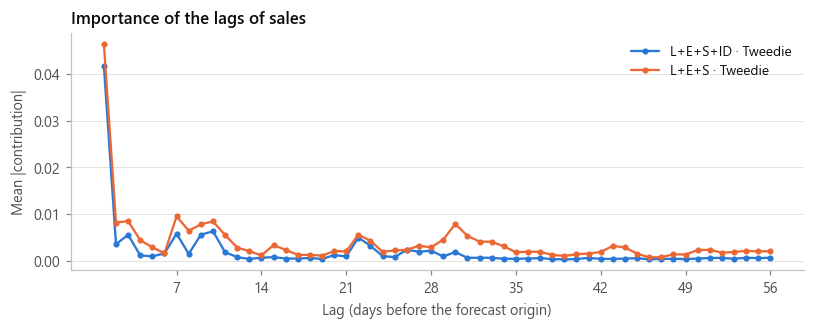

lags 1-7 carry 54% of the importance of the 56 lags


In [4]:
lags = imp.loc[F.LAG_COLS]
fig, ax = plt.subplots(figsize=(8.6, 2.8))
for name, color in zip(shap, SERIES):
    ax.plot(range(1, F.N_LAGS + 1), lags[name], color=color, marker="o", ms=3, label=name)
ax.set_xticks(range(7, F.N_LAGS + 1, 7))
ax.set_xlabel("Lag (days before the forecast origin)")
ax.set_ylabel("Mean |contribution|")
ax.set_title("Importance of the lags of sales")
ax.legend()
savefig(fig, "lag_importance", subdir="interpretation")
plt.show()
print(f"lags 1-7 carry {lags[TOP].iloc[:7].sum() / lags[TOP].sum():.0%} of the importance of the 56 lags")

## 3. How the main inputs move the forecast

Median contribution (line) and the middle half of the contributions (band) by the value of the input. The
contributions are on the log scale: a contribution of 0.5 multiplies the forecast by 1.65, one of −0.5 by 0.61.

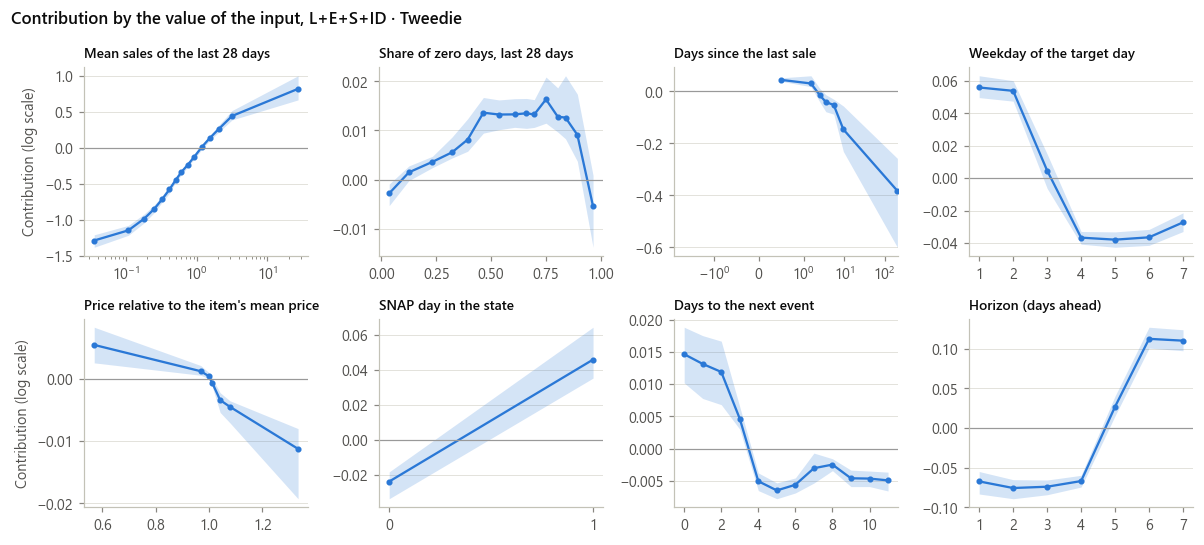

,lowest median contribution,highest median contribution,factor between them
mean_28,-1.290,0.815,8.209
zero_share_28,-0.005,0.016,1.022
days_since_sale,-0.383,0.044,1.533
wday,-0.038,0.056,1.098
rel_price,-0.011,0.005,1.017
snap,-0.024,0.046,1.072
days_to_event,-0.007,0.015,1.021
h,-0.076,0.112,1.207


In [5]:
PANELS = [("mean_28", "Mean sales of the last 28 days"), ("zero_share_28", "Share of zero days, last 28 days"),
          ("days_since_sale", "Days since the last sale"), ("wday", "Weekday of the target day"),
          ("rel_price", "Price relative to the item's mean price"), ("snap", "SNAP day in the state"),
          ("days_to_event", "Days to the next event"), ("h", "Horizon (days ahead)")]
s = shap[TOP]
fig, axes = plt.subplots(2, 4, figsize=(11, 5))
dep = {}
for ax, (col, title) in zip(axes.ravel(), PANELS):
    x = X[col].astype(float)
    if x.nunique() <= 12:
        key = x
    else:
        edges = np.unique(np.nanquantile(x, np.linspace(0, 1, 16)))
        key = pd.cut(x, edges, include_lowest=True, duplicates="drop").map(lambda b: b.mid).astype(float)
    q = s[col].groupby(key.to_numpy()).quantile([0.25, 0.5, 0.75]).unstack()
    dep[col] = q
    ax.fill_between(q.index, q[0.25], q[0.75], color=SERIES[0], alpha=0.2, lw=0)
    ax.plot(q.index, q[0.5], color=SERIES[0], marker="o", ms=3)
    ax.axhline(0, color="0.6", lw=0.8)
    if col == "mean_28":
        ax.set_xscale("log")
    if col == "days_since_sale":
        ax.set_xscale("symlog", linthresh=1)
    if x.nunique() <= 12:
        ax.set_xticks(sorted(x.unique()) if x.nunique() <= 7 else range(0, 12, 2))
    ax.set_title(title, fontsize=9)
axes[0, 0].set_ylabel("Contribution (log scale)")
axes[1, 0].set_ylabel("Contribution (log scale)")
fig.suptitle(f"Contribution by the value of the input, {TOP}", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
savefig(fig, "dependence", subdir="interpretation")
plt.show()
pd.concat(dep).rename_axis(["input", "value"]).to_csv(RESULTS / "dependence.csv")
pd.DataFrame({col: {"lowest median contribution": q[0.5].min(), "highest median contribution": q[0.5].max(),
                    "factor between them": np.exp(q[0.5].max() - q[0.5].min())} for col, q in dep.items()}).T

## 4. What the identifiers replace

The identifiers are the only difference between the two models. The table compares the importance of each
group, and of the identifiers one by one, to show which inputs lose importance when the model knows which
series a row belongs to.

In [6]:
ids = imp.loc[F.ID_COLS, [TOP]].rename(columns={TOP: "mean |contribution|"})
ids["share of the ID group"] = ids["mean |contribution|"] / ids["mean |contribution|"].sum()
change = groups.assign(change=groups[TOP] - groups[NAMES["LES_tweedie"]])
item = shap[TOP]["item_id"]
per_series = item.groupby(series).mean()
print(f"item_id: contribution of a series (mean over its forecasts) between {per_series.quantile(0.05):+.2f} and "
      f"{per_series.quantile(0.95):+.2f} for 90% of the series, i.e. a factor of {np.exp(per_series.quantile(0.05)):.2f} to "
      f"{np.exp(per_series.quantile(0.95)):.2f}")
display(change)
ids

item_id: contribution of a series (mean over its forecasts) between -0.27 and +0.05 for 90% of the series, i.e. a factor of 0.77 to 1.06


,L+E+S+ID · Tweedie,L+E+S · Tweedie,change
horizon,0.080,0.096,-0.016
L: lags of sales,0.048,0.076,-0.028
E: known in advance,0.051,0.055,-0.004
S: statistics of sales,1.021,1.086,-0.065
ID: identifiers,0.103,NaN,NaN


,mean |contribution|,share of the ID group
item_id,0.088,0.631
dept_id,0.025,0.180
cat_id,0.003,0.021
store_id,0.022,0.158
state_id,0.002,0.011


## Key findings

1. **The model is first of all a smoothed level of recent sales.** The statistics of sales carry about ten
   times more importance than any other group (1.02 against 0.05–0.10), and the mean of the last 28 days
   alone more than half of the total. This is the information the intermittent-demand methods use (ADIDA and
   TSB are smoothed levels), which is consistent with the small gain over them on single series (Section
   7.5).
2. **Single lags matter little once the statistics are present.** The 56 lags together have an importance of
   0.05; the last seven days carry 54% of it, and yesterday's sales the most.
3. **The inputs known in advance have small but systematic effects.** A SNAP day raises the forecast by about
   7%, a weekend day by about 10% against a mid-week day, the days just before an event by 1–2%; the relative
   price changes it by about 1–2% over its whole range. These effects are the same for many series at once,
   which is why they improve the aggregated levels much more than single series (Sections 7.4, 7.6).
4. **The horizon carries part of the weekly pattern.** Every origin is a Sunday, so horizons 6 and 7 are
   always a Saturday and a Sunday. The contribution of the horizon (−0.07 for days 1–4, +0.11 for days 6–7)
   is therefore mostly a weekday effect and cannot be read as a loss of accuracy with the horizon.
5. **The identifiers replace the long-run statistics.** `item_id` is the fourth most important input. With the
   identifiers the mean of the last 182 days, the share of zero days of the last 182 days and the age of the
   series lose more than half of their importance: the model reads the long-run level of a series from its
   identity instead. The identifiers matter most for intermittent series (0.12) and least for smooth ones
   (0.04).
6. **Long gaps lower the forecast.** More than a week without a sale lowers the forecast by about 14%, a very
   long gap by about 30%, beyond what the recent mean already says: the model has learned the obsolescence
   that TSB models directly.
7. **Limits.** Shapley values describe what the model uses, not what causes sales. The means over 7, 28, 56
   and 182 days are strongly correlated, so their importance is shared among them and only their sum is
   reliable. The values are on the log scale and come from one model (seed 0) and one window.